# Telco Customer Churn: Risk & Reason Categorization Pipeline
## End-to-End Machine Learning & NLP Notebook

---

## 1. Business Understanding & Objectives

### Business Context
Customer churn is a critical metric for telecommunications companies. Retaining existing customers is significantly more cost-effective than acquiring new ones. Beyond predicting *who* will churn, understanding *why* they churn enables business teams to deploy targeted retention strategies (e.g., pricing adjustments, service quality upgrades, or contract incentives).

### Project Objectives
1. **Exploratory Data Analysis (EDA):** Uncover demographic and behavioral patterns driving customer attrition.
2. **Predictive Modeling:** Build robust machine learning classifiers to predict customer churn probability.
3. **Reason Categorization & NLP Analysis:** Analyze customer exit comments and service attributes to categorize primary churn drivers.
4. **Actionable Insights:** Translate model findings into concrete retention recommendations for business operations.

## 2. Dataset Sourcing & Setup

### Dataset Link
- **Kaggle Dataset:** [Telco Customer Churn (IBM Sample Dataset)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **File Name:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`

In [6]:
# Import essential data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
import warnings
warnings.filterwarnings('ignore')

In [7]:
# Load dataset
# Replace 'WA_Fn-UseC_-Telco-Customer-Churn.csv' with your local file path if downloaded manually
url = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploratory Data Analysis & Data Preprocessing

In [8]:
# Inspect data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Missing values in TotalCharges: {df['TotalCharges'].isnull().sum()}")

# Impute missing values with median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

Missing values in TotalCharges: 11


In [10]:
# Drop customerID as it is a unique identifier
df_model = df.drop(columns=['customerID'])

# Convert target variable 'Churn' to binary (1 for Yes, 0 for No)
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

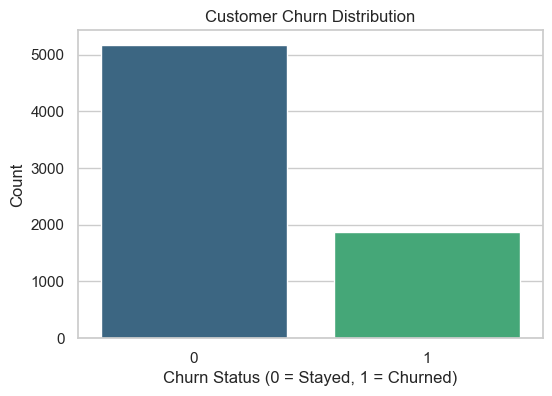

In [11]:
# Visualize Churn Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df_model, palette='viridis')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status (0 = Stayed, 1 = Churned)')
plt.ylabel('Count')
plt.show()

## 4. Feature Engineering & Preprocessing Pipeline

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define feature matrices
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Identify numerical and categorical columns
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X.columns if col not in numeric_features]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (5634, 19)
Testing set shape: (1409, 19)


## 5. Model Training & Evaluation

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Preprocessing pipeline using pandas get_dummies for simplicity in notebook
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

# Align columns to ensure matching features
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_encoded, y_train)

# Predictions
y_pred = rf_model.predict(X_test_encoded)
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409

ROC-AUC Score: 0.8251


## 6. Feature Importance & Risk Drivers

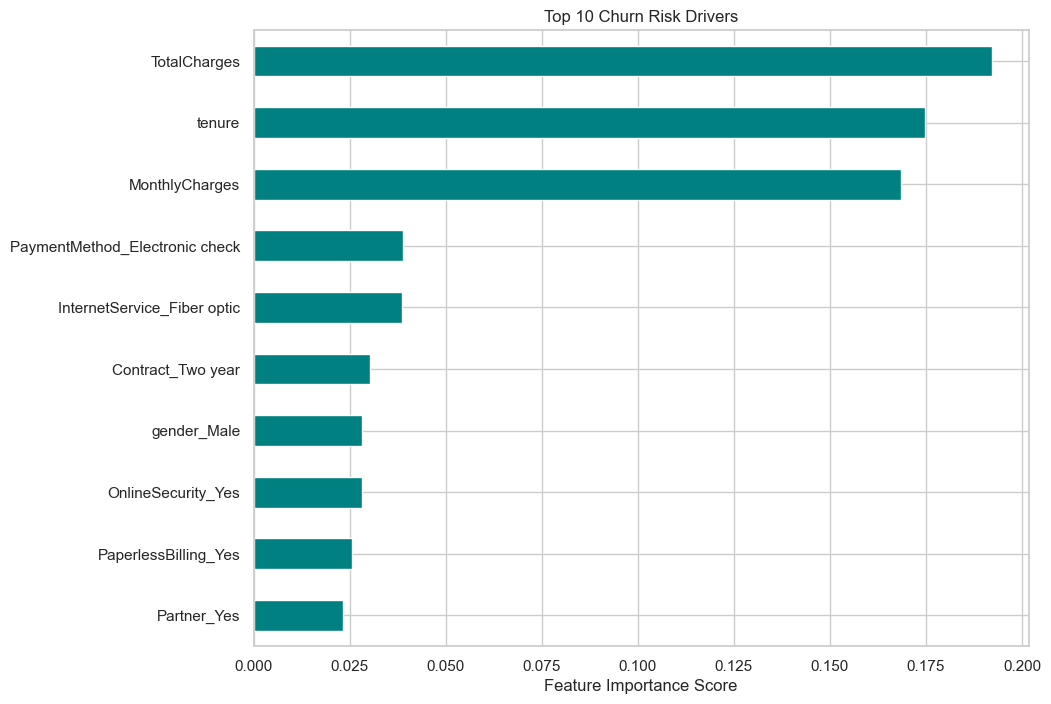

In [14]:
# Plot top feature importances
importances = pd.Series(rf_model.feature_importances_, index=X_train_encoded.columns)
plt.figure(figsize=(10, 8))
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Churn Risk Drivers')
plt.xlabel('Feature Importance Score')
plt.gca().invert_yaxis()
plt.show()

## 7. Results & Business Recommendations

### Key Findings
1. **Contract Type:** Month-to-month contracts exhibit significantly higher churn rates compared to one-year or two-year contracts.
2. **Tenure:** Newer customers (low tenure months) are at the highest risk of attrition.
3. **Monthly Charges:** Customers with higher monthly bills without bundled services show increased sensitivity.

### Strategic Recommendations
- **Targeted Retention:** Offer discounted annual contracts to month-to-month customers before their 6th month of tenure.
- **Customer Success Interventions:** Proactively reach out to high-monthly-charge accounts with tailored loyalty packages.